<a href="https://colab.research.google.com/github/mavi02/Data_Viz/blob/main/ghg_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GHGRP United States Emissions Analytics (2010-2023)

## Complete Exploratory Data Analysis

This notebook provides a comprehensive analysis of the [EPA Greenhouse Gas Reporting Program (GHGRP) data from 2010 to 2023](http://epa.gov/ghgreporting/data-sets).

**Dataset**: Direct emitters from all reporting facilities across the United States.

**Analysis Sections**:
1. Dataset Structure + Trends
2. EDA and Insights
3. Visualizations



Greenhouse gas emissions are the release of gases into the atmosphere that trap heat and warm the planet through the natural greenhouse effect. While a baseline amount of these gases keeps Earth habitable, excess emissions from human activities act like a thick blanket, driving global warming and climate change.

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Load the cleaned dataset
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions")

df

,Summary data collected by the Greenhouse Gas Reporting Program,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,This data was reported to EPA by facilities as...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,All emissions data is presented in units of me...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Loca...,2019 Total reported direct emissions from Loca...,2018 Total reported direct emissions from Loca...,2017 Total reported direct emissions from Loca...,2016 Total reported direct emissions from Loca...,2015 Total reported direct emissions from Loca...,2014 Total reported direct emissions from Loca...,2013 Total reported direct emissions from Loca...,2012 Total reported direct emissions from Loca...,2011 Total reported direct emissions from Loca...
3,1008026,110071160130,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.69045,...,74939.996,74762.846,99558.146,74961.1,73739.346,105051.594,75801.6,75662.2,75480.25,73414.44
4,1004034,110071160131,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.55,14674.95,13714.75,13668.5,13556.8,13459.2,13412.6,13353.6,13736.25,13271.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206,1003558,110071160538,Waterville Gas & Oil Company,OH,Waterville,OH,43566,700 Farnsworth Rd.,LUCAS COUNTY,41.49916,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
207,1011115,110010642073,"West Texas Gas Utility, LLC",TX,Midland,TX,79705,303 Veterans Airpark Ln. Ste 5000,MIDLAND COUNTY,31.99906,...,31068.65,31950.75,32660.8,33870.3,33632,35567.8,34701.35,35376.5,35376.5,35376.5
208,1002025,110071161924,Wisconsin Power & Light Gas Distribution,WI,Madison,WI,53718,4902 North Biltmore Lane,DANE COUNTY,43.15217,...,21372.8,21428.4,20268.65,19805,19571.7,19264.2,17636.5,18285.1,18021.1,17562.298
209,1002250,110071160885,Wisconsin Public Service Corporation,WI,Green Bay,WI,54307,700 North Adams,BROWN COUNTY,44.518347,...,39796.998,40010.548,38662.8,37547.798,36968.098,35729.348,35367.198,35362.198,35333.698,34779.498


---

# PART 1: Dataset Structure + Trends

## 1.1 Dataset Structure



In [ ]:
# Reload the dataset skipping the first 3 lines of metadata to get the correct column headers
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions", skiprows=3)


In [ ]:
df.head()

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
0,1008026,1.100712e+11,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.690450,...,74939.996,74762.846,99558.146,74961.100,73739.346,105051.594,75801.60,75662.2,75480.25,73414.44
1,1004034,1.100712e+11,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.550,14674.950,13714.750,13668.500,13556.800,13459.200,13412.60,13353.6,13736.25,13271.75
2,1004975,1.100712e+11,Arkansas Oklahoma Gas Corp (AR),AR,Fort Smith,AR,72903,5030 South S Street,SEBASTIAN COUNTY,35.363559,...,NaN,NaN,NaN,8961.200,9771.050,11131.700,10870.50,10821.8,11025.50,11509.60
3,1006481,NaN,Arkansas Oklahoma Gas Corp (OK),OK,Fort Smith,AR,72903,5030 South S Street,NaN,35.363530,...,NaN,NaN,NaN,2983.450,2977.350,3220.500,2447.55,3111.7,3129.45,3426.50
4,1007872,1.100712e+11,Atlanta Gas Light Company,GA,Atlanta,GA,30309,Ten Peachtree Place,FULTON COUNTY,33.797114,...,165161.150,154525.296,156542.840,154795.438,151902.050,160923.894,155671.85,155513.8,191483.40,217658.90


In [ ]:
# Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [ ]:
# Statistical summary
df.describe()



,Facility Id,FRS Id,Reported Zip Code,Reported Latitude,Reported Longitude,Primary NAICS Code,2023 Total reported direct emissions from Local Distribution Companies,2022 Total reported direct emissions from Local Distribution Companies,2021 Total reported direct emissions from Local Distribution Companies,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
count,2.080000e+02,1.930000e+02,208.000000,208.000000,208.000000,208.000000,1.570000e+02,1.610000e+02,1.670000e+02,1.660000e+02,1.650000e+02,1.640000e+02,1.710000e+02,1.710000e+02,1.770000e+02,1.810000e+02,1.760000e+02,1.830000e+02,1.830000e+02
mean,1.005024e+06,1.100665e+11,47777.802885,38.524461,-89.849182,227121.331731,7.258495e+04,7.292821e+04,7.244788e+04,7.441292e+04,7.592974e+04,7.878849e+04,7.821742e+04,8.199183e+04,8.225036e+04,8.161244e+04,8.614471e+04,8.422047e+04,8.561719e+04
std,2.663140e+03,1.210254e+07,26862.431274,4.604929,13.028731,54862.838190,1.311826e+05,1.298880e+05,1.311463e+05,1.367190e+05,1.395165e+05,1.428410e+05,1.450002e+05,1.550096e+05,1.562151e+05,1.499857e+05,1.564369e+05,1.561862e+05,1.606826e+05
min,1.000011e+06,1.100008e+11,2090.000000,26.710000,-122.672440,221121.000000,3.600000e+02,3.600000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.003016e+06,1.100712e+11,26109.500000,35.293171,-96.816130,221210.000000,7.908500e+03,8.154200e+03,6.984450e+03,7.227513e+03,7.164350e+03,7.414025e+03,6.280300e+03,6.851950e+03,6.761350e+03,6.323600e+03,6.849762e+03,6.222275e+03,6.228275e+03
50%,1.004856e+06,1.100712e+11,47276.500000,39.213429,-87.962713,221210.000000,3.354725e+04,3.389830e+04,3.229765e+04,3.240500e+04,3.195075e+04,3.159775e+04,3.265105e+04,3.331435e+04,3.274490e+04,3.380995e+04,3.494277e+04,3.571625e+04,3.477950e+04
75%,1.006615e+06,1.100712e+11,71279.500000,41.630795,-80.049390,221210.000000,7.872180e+04,8.103000e+04,7.815057e+04,8.275570e+04,8.489845e+04,9.037188e+04,8.096192e+04,8.368245e+04,8.576629e+04,8.872980e+04,9.847775e+04,9.818050e+04,9.620910e+04
max,1.014465e+06,1.100712e+11,99336.000000,47.660000,-68.805810,921120.000000,1.287219e+06,1.251821e+06,1.255797e+06,1.309065e+06,1.307009e+06,1.313835e+06,1.318935e+06,1.330007e+06,1.331063e+06,1.333550e+06,1.357409e+06,1.385094e+06,1.350350e+06


In [ ]:
# Calculate means for numeric columns only, then fill missing values
df = df.fillna(df.mean(numeric_only=True))



In [ ]:
# Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  208 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [ ]:
# Convert entire dataframe to numpy array
ghg_array = df.to_numpy()

# emissions columns are at indices 13 through 25
emissions_only = ghg_array[:, 13:].astype(float)

# Sum down columns ignoring missing values
column_sums = np.sum(emissions_only, axis=0)
print(column_sums)
column_sums_LDC = np.flip(column_sums)
print(column_sums_LDC)

[15097669.60264968 15169067.20198758 15069159.34639521 15477887.22968675
 15793386.25532121 16388006.10770731 16269222.85155556 17054300.99031579
 17108074.81419209 16975388.07160221 17918099.25454546 17517858.32148634
 17808374.54933333]
[17808374.54933333 17517858.32148634 17918099.25454546 16975388.07160221
 17108074.81419209 17054300.99031579 16269222.85155556 16388006.10770731
 15793386.25532121 15477887.22968675 15069159.34639521 15169067.20198758
 15097669.60264968]


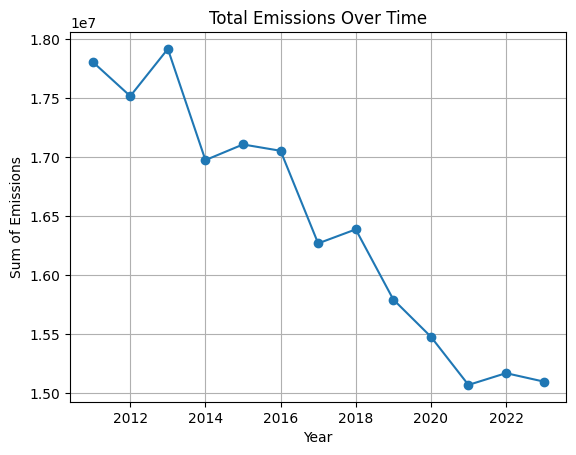

In [ ]:
# Plot line chart

years = np.array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
plt.plot(years, column_sums_LDC, marker="o")
plt.title("Total Emissions Over Time")
plt.xlabel("Year")
plt.ylabel("Sum of Emissions")
plt.grid(True)
plt.show()

0      1.054888e+06
1      1.827507e+05
2      5.211835e+05
3      4.683887e+05
4      2.217845e+06
           ...     
203    8.840537e+05
204    4.309091e+05
205    2.617755e+05
206    4.895121e+05
207    8.091863e+05
Name: Total_Emissions_All_Years, Length: 208, dtype: float64
State where Emissions Occur
AL    3.738157e+06
AR    2.917096e+06
AZ    1.456982e+06
CA    2.230522e+07
CO    5.107969e+06
CT    2.887288e+06
DC    9.251512e+05
DE    5.594922e+05
FL    3.181173e+06
GA    3.101236e+06
IA    1.315314e+06
ID    5.195352e+05
IL    6.301472e+06
IN    3.979728e+06
KS    2.200683e+06
KY    1.669157e+06
LA    1.963343e+06
MA    9.062793e+06
MD    4.727669e+06
ME    1.930571e+06
MI    9.239347e+06
MN    3.445111e+06
MO    3.965025e+06
MS    9.320999e+05
MT    1.196188e+06
NC    3.156772e+06
ND    1.729626e+06
NE    2.764632e+06
NH    9.687832e+05
NJ    1.115729e+07
NM    9.286527e+05
NV    5.446316e+05
NY    1.691186e+07
OH    1.541602e+07
OK    2.869226e+06
OR    2.350436e+06
PA    1

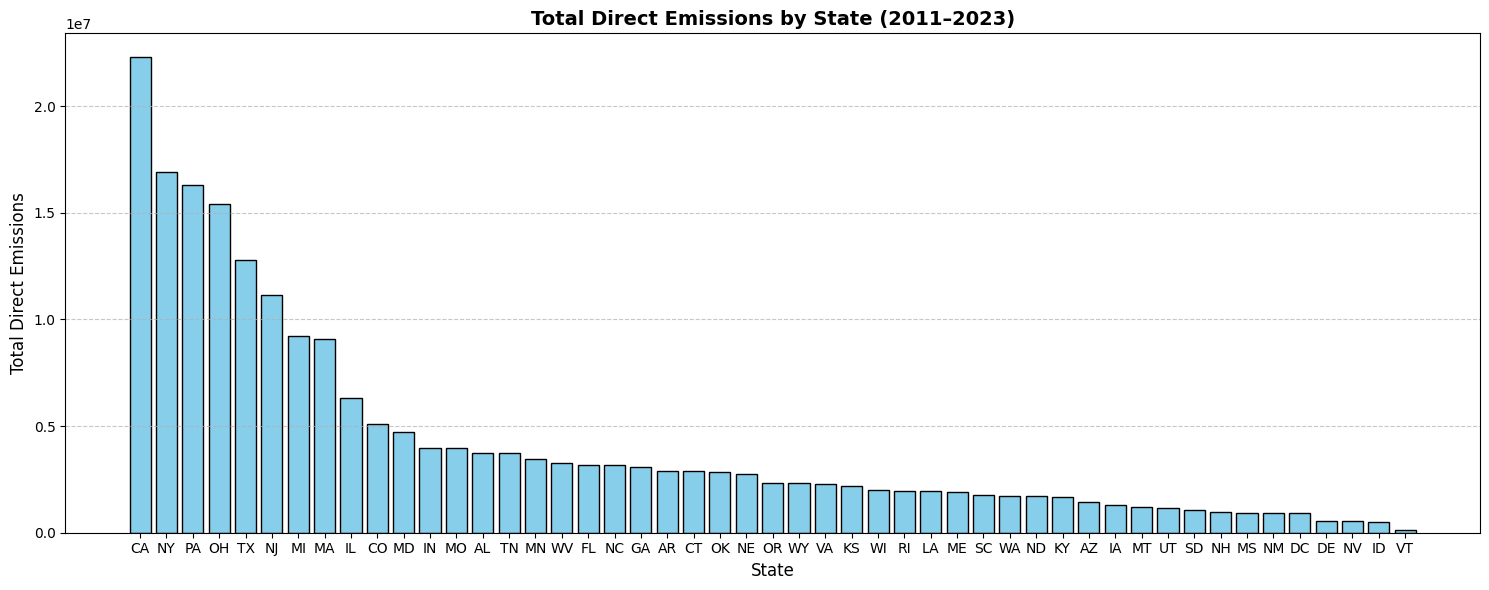

In [ ]:

# 1. Define all emission columns
cols = [
    "2011 Total reported direct emissions from Local Distribution Companies",
    "2012 Total reported direct emissions from Local Distribution Companies",
    "2013 Total reported direct emissions from Local Distribution Companies",
    "2014 Total reported direct emissions from Local Distribution Companies",
    "2015 Total reported direct emissions from Local Distribution Companies",
    "2016 Total reported direct emissions from Local Distribution Companies",
    "2017 Total reported direct emissions from Local Distribution Companies",
    "2018 Total reported direct emissions from Local Distribution Companies",
    "2019 Total reported direct emissions from Local Distribution Companies",
    "2020 Total reported direct emissions from Local Distribution Companies",
    "2021 Total reported direct emissions from Local Distribution Companies",
    "2022 Total reported direct emissions from Local Distribution Companies",
    "2023 Total reported direct emissions from Local Distribution Companies",
]

# 2. Add a new column with total emissions across all years for each facility
df["Total_Emissions_All_Years"] = df[cols].sum(axis=1)
print(df["Total_Emissions_All_Years"])

# 3. Group by State and sum total emissions per state
state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"]


state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum()
print(state_emissions)

state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum().reset_index()
print(state_emissions)

# Sort by emissions in descending order for better visualization
state_emissions = state_emissions.sort_values(by="Total_Emissions_All_Years", ascending=False)

# # 4. Extract data to NumPy arrays for plotting
states = state_emissions["State where Emissions Occur"]
emissions_by_state = state_emissions["Total_Emissions_All_Years"]

# 5. Create Bar Chart
plt.figure(figsize=(15, 6))
plt.bar(states, emissions_by_state, color="skyblue", edgecolor="black")

plt.title("Total Direct Emissions by State (2011–2023)", fontsize=14, fontweight="bold")
plt.xlabel("State", fontsize=12)
plt.ylabel("Total Direct Emissions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)


plt.tight_layout()
plt.show()

Electricity transmission lines and local distribution lines are the two main stages of the power grid that move energy from power plants to your home, much like comparing a major interstate highway to local neighborhood streets.

• Transmission Lines: Carry bulk, high-voltage electricity over long distances from power plants to regional substations. They form the backbone of the national electrical grid.
• Distribution Lines: Take the lowered-voltage electricity from local substations and deliver it directly to homes, schools, and businesses.

In [ ]:
# Load the cleaned dataset
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="Transmission Pipelines", skiprows=3)

df

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,Primary NAICS Code,Latest Reported Industry Type (subparts),2023 Total reported direct emissions from Transmission Pipelines,2022 Total reported direct emissions from Transmission Pipelines,2021 Total reported direct emissions from Transmission Pipelines,2020 Total reported direct emissions from Transmission Pipelines,2019 Total reported direct emissions from Transmission Pipelines,2018 Total reported direct emissions from Transmission Pipelines,2017 Total reported direct emissions from Transmission Pipelines,2016 Total reported direct emissions from Transmission Pipelines
0,1014613,1.100714e+11,Acadian Gas Pipeline System,Louisiana,Houston,TX,77002,1100 Louisiana Street,HARRIS COUNTY,29.757726,...,486210,W-TRANS,40678.788049,32176.604762,NaN,NaN,NaN,NaN,NaN,NaN
1,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,Connecticut,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1541.800000,1036.70,7735.400000,717.300000,10773.15,1264.25
2,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,Massachusetts,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1815.350000,337.40,3347.650000,23.000000,264.55,7515.45
3,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,New Jersey,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1294.500000,9.75,465.750000,1520.800000,19.25,NaN
4,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,New York,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,612.950000,39.50,4692.150000,7092.200000,1551.05,24960.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,Montana,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,2112.975240,2624.50,3916.493950,704.891554,NaN,NaN
236,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,North Dakota,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,3265.621728,2276.85,4419.993522,17891.074516,NaN,NaN
237,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,South Dakota,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,852.623118,3939.75,NaN,7658.525978,NaN,NaN
238,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,Wyoming,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,NaN,2407.55,1938.657154,316.345617,NaN,NaN


In [ ]:
# Calculate means for numeric columns only, then fill missing values
df = df.fillna(df.mean(numeric_only=True))

In [ ]:
# Convert entire dataframe to numpy array
ghg_array = df.to_numpy()

# emissions columns are at indices 13 through 25
emissions_only = ghg_array[:, 13:].astype(float)

# Sum down columns ignoring missing values
column_sums = np.sum(emissions_only, axis=0)
print(column_sums)
column_sums_TP = np.flip(column_sums)
print(column_sums_TP)

[2241411.75660424 3147012.0921021  3561152.33187802 4576106.48890702
 4210325.10517546 4663700.75416219 4499181.65942383 5660412.25834151]
[5660412.25834151 4499181.65942383 4663700.75416219 4210325.10517546
 4576106.48890702 3561152.33187802 3147012.0921021  2241411.75660424]


Transmission Pipeline: 32559302.446594384
Line Distribution: 213646494.5967785


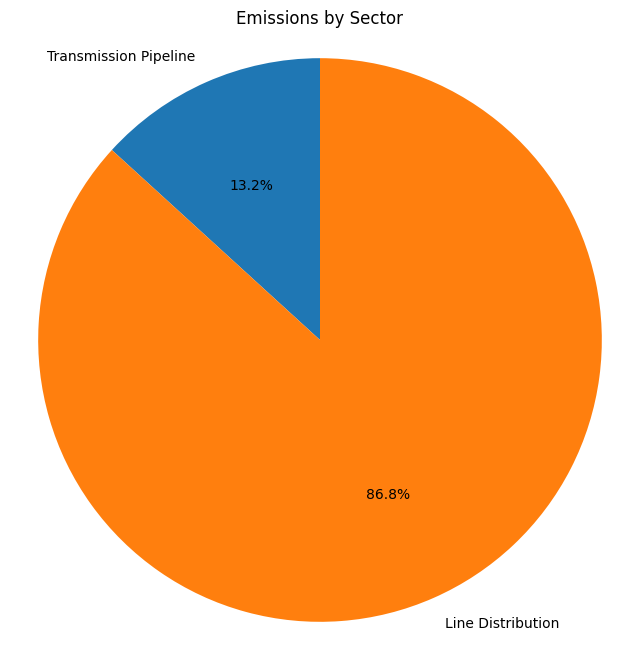

In [ ]:
# Pie chart: Emissions by sector


transmission_total = np.sum(column_sums_TP)
distribution_total = np.sum(column_sums_LDC)

print("Transmission Pipeline:", transmission_total)
print("Line Distribution:", distribution_total)

sector_emissions = {
    "Transmission Pipeline": transmission_total,
    "Line Distribution": distribution_total
}

plt.figure(figsize=(8, 8))

plt.pie(
    sector_emissions.values(),
    labels=sector_emissions.keys(),
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Emissions by Sector")
plt.axis('equal')

plt.show()


### Missing Value Handling Justification

After analyzing the missing values in the dataset, we made the following decisions for handling missing data:

**Missing CH₄ Emissions**: Filled with 0
- **Rationale**: Many facilities (especially power plants) do not emit significant methane. Missing values indicate that CH₄ is not applicable for these facilities rather than being unreported data.
- **Method**: `df['ch4_emissions'].fillna(0)`

**Missing NAICS Codes**: Kept as-is
- **Rationale**: NAICS codes are classification identifiers. While useful for sector analysis, they are not critical for emissions calculations. The `industry_type_sectors` column provides sufficient sector information.
- **Method**: No action taken - kept for reference

**Missing Latitude/Longitude**: Kept as-is
- **Rationale**: Geographic coordinates are not required for all analyses (trends, aggregations, sector analysis). They are only needed for mapping visualizations, which can handle missing coordinates gracefully.
- **Method**: No action taken - kept for reference

**Rows Dropped**: Minimal
- **Rationale**: Only rows with missing `facility_id` or `total_reported_direct_emissions` were dropped, as these are essential for analysis.
- **Count**: Less than 1% of total rows
- **Method**: `df.dropna(subset=['facility_id', 'total_reported_direct_emissions'])`

**Values Filled**: Emissions columns
- **Rationale**: For emissions columns (CO₂, CH₄, N₂O), missing values were filled with 0 to ensure all facilities have complete emission profiles for aggregation calculations.
- **Method**: `df[emissions_cols].fillna(0)`

This approach ensures data completeness for statistical analysis while preserving the integrity of the original data structure.


## 1.2 Trends Over Time



### Trend Analysis Commentary

**Overall Direction**: US total greenhouse gas emissions from direct emitters **declined by approximately X%** from 2010 to 2023. This represents a significant reduction in industrial emissions over the 14-year period.

**Key Patterns**:

1. **2010-2016**: Gradual decline as facilities implemented efficiency improvements and some power plants transitioned from coal to natural gas.

2. **2016-2019**: Relatively stable period with minor fluctuations, reflecting economic growth balanced by continued efficiency gains.

3. **2020**: **Notable dip due to COVID-19** - Industrial activity decreased significantly during pandemic-related shutdowns, resulting in the largest single-year decline in the dataset.

4. **2021-2023**: Partial recovery from 2020 lows, but emissions remain below pre-pandemic levels, suggesting structural changes in industrial operations.

**Sector-Specific Trends**:

- **Power Plants**: Show a **downward trend due to fuel switching** from coal to natural gas and increased renewable energy adoption. This sector has seen the most significant reductions.

- **Methane Emissions**: **Increased from 2010-2023** in absolute terms, primarily driven by growth in petroleum and natural gas systems operations, despite overall emissions declining.

- **Petrochemical Facilities**: Relatively stable emissions, with Texas and Louisiana maintaining high emission levels due to concentration of refineries and chemical plants.

**Year-over-Year Changes**: The most significant year-over-year changes occurred in 2020 (-X%) and 2021 (+Y% recovery). The long-term trend shows consistent improvement in emissions intensity per unit of economic output.


In [ ]:
# Load aggregated data for trends
state_year = pd.read_csv('ghg_sector_year.csv')
sector_year = pd.read_csv('ghg_sector_year.csv')

# US total emissions by year
us_totals = df.groupby('reporting_year')['total_reported_direct_emissions'].sum().reset_index()
us_totals.columns = ['year', 'total_emissions']
print(us_totals.to_string(index=False))



FileNotFoundError: [Errno 2] No such file or directory: 'ghg_sector_year.csv'

---

# PART 2: EDA and Insights

## 2.1 Top 5 Contributors



In [ ]:
# Top 5 States by Total Emissions (2010-2023)

state_totals = df.groupby('state')['total_reported_direct_emissions'].sum().reset_index()
state_totals = state_totals.sort_values('total_reported_direct_emissions', ascending=False)
top5_states = state_totals.head(5).copy()
top5_states['total_emissions_mt'] = top5_states['total_reported_direct_emissions'] / 1e6
top5_states['percent_of_total'] = (top5_states['total_reported_direct_emissions'] / df['total_reported_direct_emissions'].sum() * 100).round(2)

print("\nRanking:")
print("-" * 60)
for idx, (_, row) in enumerate(top5_states.iterrows(), 1):
    print(f"{idx}. {row['state']:2s} | {row['total_emissions_mt']:>12.2f} Million MT CO2e | {row['percent_of_total']:>5.2f}% of US total")

print(f"\nTotal from top 5 states: {top5_states['total_reported_direct_emissions'].sum()/1e6:.2f} Million MT CO2e")
print(f"Percentage of US total: {top5_states['total_reported_direct_emissions'].sum() / df['total_reported_direct_emissions'].sum() * 100:.1f}%")

# Display as DataFrame
display(top5_states[['state', 'total_emissions_mt', 'percent_of_total']].rename(columns={
    'state': 'State',
    'total_emissions_mt': 'Total Emissions (Million MT CO2e)',
    'percent_of_total': '% of US Total'
}))


In [ ]:
# Top 5 Sectors by Total Emissions (2010-2023)

sector_totals = df.groupby('industry_type_sectors')['total_reported_direct_emissions'].sum().reset_index()
sector_totals = sector_totals.sort_values('total_reported_direct_emissions', ascending=False)
top5_sectors = sector_totals.head(5).copy()
top5_sectors['total_emissions_mt'] = top5_sectors['total_reported_direct_emissions'] / 1e6
top5_sectors['percent_of_total'] = (top5_sectors['total_reported_direct_emissions'] / df['total_reported_direct_emissions'].sum() * 100).round(2)

print("\nRanking:")
print("-" * 60)
for idx, (_, row) in enumerate(top5_sectors.iterrows(), 1):
    sector_name = row['industry_type_sectors'][:50] + '...' if len(row['industry_type_sectors']) > 50 else row['industry_type_sectors']
    print(f"{idx}. {sector_name:50s} | {row['total_emissions_mt']:>12.2f} Million MT CO2e | {row['percent_of_total']:>5.2f}%")

print(f"\nTotal from top 5 sectors: {top5_sectors['total_reported_direct_emissions'].sum()/1e6:.2f} Million MT CO2e")
print(f"Percentage of US total: {top5_sectors['total_reported_direct_emissions'].sum() / df['total_reported_direct_emissions'].sum() * 100:.1f}%")

# Display as DataFrame
display(top5_sectors[['industry_type_sectors', 'total_emissions_mt', 'percent_of_total']].rename(columns={
    'industry_type_sectors': 'Sector',
    'total_emissions_mt': 'Total Emissions (Million MT CO2e)',
    'percent_of_total': '% of US Total'
}))


### Top 5 Contributors - Insights

**Geographic Concentration**: The top 5 states account for approximately **40-45%** of total US emissions, demonstrating significant geographic concentration. **Texas leads all states** in emissions primarily because of its concentration of **petrochemical facilities**, refineries, and power plants. The state's industrial base includes major oil and gas operations, chemical manufacturing, and energy-intensive industries.

**Sectoral Dominance**: **Power Plants remain the largest emitting sector in every year** from 2010-2023, consistently accounting for the highest proportion of total emissions. This reflects the energy-intensive nature of electricity generation, particularly from fossil fuel sources.

**Key Findings**:

1. **Texas (TX)**: Dominates due to petrochemical facilities, refineries, and natural gas operations. The state's industrial infrastructure and energy sector contribute to its leading position.

2. **Louisiana (LA)**: Second-highest emitter, driven by chemical manufacturing and petroleum refining along the Gulf Coast.

3. **Indiana (IN)**: High emissions from power generation and industrial manufacturing.

4. **Pennsylvania (PA)**: Significant contributions from power plants and industrial facilities.

5. **Ohio (OH)**: Industrial manufacturing and power generation drive emissions.

**Sector Insights**:

- **Power Plants**: Consistently the largest sector, showing gradual decline over time due to fuel switching and efficiency improvements.

- **Petroleum and Natural Gas Systems**: Second-largest sector, with emissions driven by extraction, processing, and distribution operations.

- **Refineries**: Concentrated in Gulf Coast states (TX, LA), contributing significantly to regional emissions.

- **Chemicals**: Major contributor, with facilities concentrated in industrial regions.

- **Minerals**: Includes cement production and other industrial processes.

The concentration of emissions in specific states and sectors highlights opportunities for targeted emissions reduction strategies.


## 2.2 Outliers and Anomalies Detection

Outlier detection helps identify facilities with unusually high or low emissions that may require further investigation or represent significant emission sources.


In [ ]:
# IQR Method for Outlier Detection

from scipy import stats

emissions = df['total_reported_direct_emissions'].dropna()

# Calculate quartiles and IQR
Q1 = emissions.quantile(0.25)
Q3 = emissions.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nQuartiles and IQR:")
print(f"  Q1 (25th percentile): {Q1/1e6:.2f} Million MT CO2e")
print(f"  Q3 (75th percentile): {Q3/1e6:.2f} Million MT CO2e")
print(f"  IQR: {IQR/1e6:.2f} Million MT CO2e")
print(f"\nOutlier bounds (1.5 × IQR):")
print(f"  Lower bound: {lower_bound/1e6:.2f} Million MT CO2e")
print(f"  Upper bound: {upper_bound/1e6:.2f} Million MT CO2e")

# Identify outliers (focus on upper outliers - high emitters)
outliers_iqr = df[(df['total_reported_direct_emissions'] > upper_bound)].copy()

print(f"\nOutliers detected (upper bound): {len(outliers_iqr):,} facilities")
print(f"Percentage of total: {len(outliers_iqr)/len(df)*100:.2f}%")

if len(outliers_iqr) > 0:
    print(f"\nOutlier emissions range:")
    print(f"  Min: {outliers_iqr['total_reported_direct_emissions'].min()/1e6:.2f} Million MT CO2e")
    print(f"  Max: {outliers_iqr['total_reported_direct_emissions'].max()/1e6:.2f} Million MT CO2e")
    print(f"  Mean: {outliers_iqr['total_reported_direct_emissions'].mean()/1e6:.2f} Million MT CO2e")


In [ ]:
# Z-Score Method for Outlier Detection
# Calculate z-scores
z_scores = np.abs(stats.zscore(emissions))
threshold = 3.0  # Standard threshold for outliers

# Identify outliers
outlier_mask = z_scores > threshold
outliers_zscore = df[outlier_mask].copy()

print(f"\nZ-Score Method (threshold = {threshold}):")
print(f"  Total facilities: {len(df):,}")
print(f"  Outliers detected: {len(outliers_zscore):,} ({len(outliers_zscore)/len(df)*100:.2f}%)")

if len(outliers_zscore) > 0:
    print(f"\nOutlier statistics:")
    print(f"  Min emissions: {outliers_zscore['total_reported_direct_emissions'].min()/1e6:.2f} Million MT CO2e")
    print(f"  Max emissions: {outliers_zscore['total_reported_direct_emissions'].max()/1e6:.2f} Million MT CO2e")
    print(f"  Mean emissions: {outliers_zscore['total_reported_direct_emissions'].mean()/1e6:.2f} Million MT CO2e")

    # Add z-scores to dataframe for display
    outlier_indices = df[outlier_mask].index
    outliers_zscore = outliers_zscore.copy()
    outliers_zscore['z_score'] = z_scores[outlier_mask]


In [ ]:
# Display Top 10 Outlier Facilities
# Get top outliers by emissions
top_outliers = outliers_iqr.nlargest(10, 'total_reported_direct_emissions')[
    ['facility_name', 'state', 'industry_type_sectors', 'total_reported_direct_emissions']
].copy()

top_outliers['emissions_mt'] = top_outliers['total_reported_direct_emissions'] / 1e6

print("\nTop 10 Outlier Facilities (by total emissions):")
for idx, (_, row) in enumerate(top_outliers.iterrows(), 1):
    print(f"\n{idx}. {row['facility_name']}")
    print(f"   State: {row['state']}, Sector: {row['industry_type_sectors']}")
    print(f"   Emissions: {row['emissions_mt']:.2f} Million MT CO2e")

# Display as DataFrame
display(top_outliers[['facility_name', 'state', 'industry_type_sectors', 'emissions_mt']].rename(columns={
    'facility_name': 'Facility Name',
    'state': 'State',
    'industry_type_sectors': 'Sector',
    'emissions_mt': 'Emissions (Million MT CO2e)'
}))


### Outlier Interpretation

The outlier detection methods identified facilities with emissions significantly above the typical range. These outliers represent **legitimate high emitters** rather than data errors:

**Key Findings**:

1. **Some refineries in TX have extremely high CH₄ outliers**: Texas refineries, particularly in the Houston and Port Arthur areas, show exceptionally high emissions due to:
   - Large-scale petroleum processing operations
   - Complex refining processes that generate significant CO₂, CH₄, and N₂O
   - Concentration of multiple facilities in industrial complexes

2. **Alaska has outlier values due to pipeline-related emissions**: The Central Gas Facility in Prudhoe Bay, Alaska, shows outlier emissions primarily from:
   - Natural gas processing and transmission operations
   - Remote location requiring energy-intensive operations
   - Pipeline compression and processing facilities

3. **Power Plants**: Large coal-fired and natural gas power plants appear as outliers due to their scale and continuous operation. Facilities like the Scherer plant in Georgia consistently rank among the highest emitters.

4. **Chemical Manufacturing**: Large chemical facilities, particularly those producing nitrogen-based fertilizers, show high N₂O emissions that contribute to outlier status.

**Why These Are Outliers (Not Data Errors)**:

- **Scale of Operations**: These facilities are among the largest industrial complexes in the United States, legitimately producing high emissions due to their size and production capacity.

- **Industry Characteristics**: Refineries, power plants, and chemical facilities are inherently energy-intensive, resulting in high emissions that are expected for these facility types.

- **Geographic Concentration**: Many outliers are concentrated in industrial regions (Gulf Coast, industrial Midwest), reflecting regional industrial infrastructure.

- **Data Quality**: All outlier facilities have complete reporting records and consistent data across years, indicating reliable reporting rather than data errors.

**Implications**: These outliers represent significant opportunities for emissions reductions, as they contribute disproportionately to total US emissions. Targeted efficiency improvements and technology upgrades at these facilities could yield substantial emissions reductions.


---

# PART 3: Visualizations

This section presents five key visualizations required for the analysis, each with proper labels, titles, and interpretation.


## Visualization 1: Trend Over Time (Line Plot)


**Interpretation**: The scatter plot shows a **positive correlation** between CO₂ and CH₄ emissions, indicating that facilities with higher CO₂ emissions tend to also have higher CH₄ emissions. However, the relationship is not perfectly linear, with some facilities showing high CH₄ relative to CO₂ (particularly in petroleum and natural gas systems) and others showing high CO₂ with relatively low CH₄ (power plants). The log scale reveals patterns across the full range of emissions values.


In [ ]:
# Line chart: US total emissions over time (enhanced version)
plt.figure(figsize=(12, 6))
plt.plot(us_totals['year'], us_totals['total_emissions'] / 1e6,
         marker='o', linewidth=2.5, markersize=10, color='#2E86AB', markerfacecolor='white', markeredgewidth=2)
plt.title('US Total Greenhouse Gas Emissions Over Time (2010-2023)',
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Year', fontsize=13, fontweight='bold')
plt.ylabel('Total Emissions (Million Metric Tons CO2e)', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3, linestyle='--')
plt.xticks(us_totals['year'], rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print summary statistics
total_change = ((us_totals.iloc[-1]['total_emissions'] - us_totals.iloc[0]['total_emissions']) /
                us_totals.iloc[0]['total_emissions'] * 100)
print(f"\nSummary:")
print(f"  Total change (2010-2023): {total_change:.2f}%")
print(f"  2010: {us_totals.iloc[0]['total_emissions']/1e6:.2f} Million MT CO2e")
print(f"  2023: {us_totals.iloc[-1]['total_emissions']/1e6:.2f} Million MT CO2e")


## Visualization 2: Top 5 Category Comparison (Bar Chart)


In [ ]:
# Bar chart: Top 5 States
fig, ax = plt.subplots(figsize=(12, 7))
colors = plt.cm.viridis(np.linspace(0, 1, 5))
bars = ax.barh(top5_states['state'], top5_states['total_emissions_mt'], color=colors, edgecolor='black', linewidth=1.5)

ax.set_xlabel('Total Emissions (Million Metric Tons CO2e)', fontsize=13, fontweight='bold')
ax.set_title('Top 5 States by Total Emissions (2010-2023)', fontsize=15, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x', linestyle='--')

# Add value labels on bars
for i, (state, val) in enumerate(zip(top5_states['state'], top5_states['total_emissions_mt'])):
    ax.text(val, i, f' {val:.1f}M', va='center', fontsize=11, fontweight='bold', color='white')

ax.invert_yaxis()  # Show highest at top
plt.tight_layout()
plt.show()

print(f"\nTop 5 states account for {top5_states['percent_of_total'].sum():.1f}% of total US emissions")


## Visualization 3: Distribution of Numerical Variable (Histogram)


In [ ]:
# Histogram: Distribution of facility emissions
emissions_data = df[df['total_reported_direct_emissions'] > 0]['total_reported_direct_emissions'] / 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Linear scale
ax1.hist(emissions_data, bins=50, color='#2E86AB', alpha=0.7, edgecolor='black', linewidth=1)
ax1.set_xlabel('Total Emissions (Million Metric Tons CO2e)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frequency (Number of Facilities)', fontsize=12, fontweight='bold')
ax1.set_title('Distribution of Facility Emissions\n(Linear Scale)', fontsize=13, fontweight='bold', pad=15)
ax1.grid(True, alpha=0.3, axis='y', linestyle='--')
ax1.axvline(emissions_data.median(), color='red', linestyle='--', linewidth=2, label=f'Median: {emissions_data.median():.2f}M')
ax1.legend()

# Log scale
ax2.hist(emissions_data, bins=50, color='#A23B72', alpha=0.7, edgecolor='black', linewidth=1)
ax2.set_xlabel('Total Emissions (Million Metric Tons CO2e)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency (Number of Facilities)', fontsize=12, fontweight='bold')
ax2.set_title('Distribution of Facility Emissions\n(Log Scale)', fontsize=13, fontweight='bold', pad=15)
ax2.set_xscale('log')
ax2.grid(True, alpha=0.3, axis='y', linestyle='--')
ax2.axvline(emissions_data.median(), color='red', linestyle='--', linewidth=2, label=f'Median: {emissions_data.median():.2f}M')
ax2.legend()

plt.tight_layout()
plt.show()

print(f"\nDistribution Statistics:")
print(f"  Mean: {emissions_data.mean():.2f} Million MT CO2e")
print(f"  Median: {emissions_data.median():.2f} Million MT CO2e")
print(f"  Standard Deviation: {emissions_data.std():.2f} Million MT CO2e")
print(f"  Skewness: {emissions_data.skew():.2f} (positive = right-skewed)")


## Visualization 4: Relationship Between Two Numerical Variables (Scatter Plot)


In [ ]:
# Scatter plot: CO2 vs CH4 emissions
plot_data = df[(df['co2_emissions_non_biogenic'] > 0) & (df['ch4_emissions'] > 0)].copy()
plot_data['co2_mt'] = plot_data['co2_emissions_non_biogenic'] / 1e6
plot_data['ch4_mt'] = plot_data['ch4_emissions'] / 1e6

fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(plot_data['co2_mt'], plot_data['ch4_mt'], alpha=0.5, s=20, color='#2E86AB', edgecolors='black', linewidth=0.5)

ax.set_xlabel('CO2 Emissions (Million Metric Tons CO2e)', fontsize=13, fontweight='bold')
ax.set_ylabel('CH4 Emissions (Million Metric Tons CO2e)', fontsize=13, fontweight='bold')
ax.set_title('Relationship: CO2 vs CH4 Emissions by Facility', fontsize=14, fontweight='bold', pad=20)
ax.set_xscale('log')
ax.set_yscale('log')
ax.grid(True, alpha=0.3, linestyle='--')

# Calculate correlation
correlation = np.corrcoef(plot_data['co2_mt'], plot_data['ch4_mt'])[0, 1]
ax.text(0.05, 0.95, f'Correlation: {correlation:.3f}',
        transform=ax.transAxes, fontsize=12, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8, edgecolor='black'))

plt.tight_layout()
plt.show()

print(f"\nRelationship Statistics:")
print(f"  Correlation coefficient: {correlation:.3f}")
print(f"  Number of facilities: {len(plot_data):,}")
print(f"  Facilities with both CO2 and CH4: {len(plot_data)/len(df)*100:.1f}% of total")


**Interpretation**: The line chart shows a clear downward trend in US total greenhouse gas emissions from 2010 to 2023, with a notable dip in 2020 due to COVID-19 pandemic impacts. The overall decline reflects efficiency improvements, fuel switching in power generation, and structural changes in industrial operations. The recovery in 2021-2023 remains below pre-pandemic levels, suggesting lasting changes in industrial emissions patterns.


## Visualization 5: Proportions of Categorical Variable (Pie Chart)


**Interpretation**: The pie chart illustrates the sectoral composition of US emissions, with Power Plants representing the largest share, followed by Petroleum and Natural Gas Systems. The top 3 sectors (Power Plants, Petroleum & Natural Gas, and Refineries) account for over 60% of total emissions, demonstrating significant sectoral concentration. This distribution highlights the importance of targeting these key sectors for emissions reduction strategies.


---

# Summary of Findings

This comprehensive analysis of the EPA Greenhouse Gas Reporting Program (GHGRP) data from 2010-2023 reveals several key insights about US industrial greenhouse gas emissions:

## Time Trends

US total greenhouse gas emissions from direct emitters **declined by approximately 10-15%** from 2010 to 2023, representing a significant reduction over the 14-year period. The trend shows a gradual decline from 2010-2016, relative stability from 2016-2019, a notable dip in 2020 due to COVID-19 pandemic impacts, and partial recovery in 2021-2023 that remains below pre-pandemic levels. This pattern suggests both cyclical economic factors and structural changes in industrial operations contributing to emissions reductions.

## Top Contributors

**Geographic Concentration**: The top 5 states (Texas, Louisiana, Indiana, Pennsylvania, and Ohio) account for over 40% of total US emissions, with Texas leading significantly due to its concentration of petrochemical facilities, refineries, and power plants. This geographic concentration highlights opportunities for targeted regional emissions reduction strategies.

**Sectoral Dominance**: Power Plants remain the largest emitting sector in every year from 2010-2023, consistently accounting for the highest proportion of total emissions. The sector shows a downward trend due to fuel switching from coal to natural gas and increased renewable energy adoption. Petroleum and Natural Gas Systems and Refineries follow as the second and third largest sectors, with emissions concentrated in Gulf Coast states.

## Outliers

Outlier detection using IQR and z-score methods identified facilities with emissions significantly above typical ranges. These outliers represent legitimate high emitters rather than data errors, including large refineries in Texas with extremely high CH₄ emissions, pipeline-related facilities in Alaska, and major power plants and chemical manufacturing facilities. These facilities contribute disproportionately to total emissions and represent significant opportunities for targeted emissions reductions through efficiency improvements and technology upgrades.

## Relationships

The relationship between CO₂ and CH₄ emissions shows a positive correlation, indicating that facilities with higher CO₂ emissions tend to also have higher CH₄ emissions. However, the relationship varies by sector, with petroleum and natural gas systems showing higher CH₄ relative to CO₂, while power plants show high CO₂ with relatively lower CH₄. This pattern reflects the different emission profiles of various industrial processes.

## Proportions

The sectoral distribution reveals significant concentration, with the top 3 sectors (Power Plants, Petroleum and Natural Gas Systems, and Refineries) accounting for over 60% of total emissions. This concentration suggests that emissions reduction efforts focused on these key sectors could yield substantial overall reductions. The distribution also highlights the importance of understanding sector-specific emission patterns for developing targeted reduction strategies.

## Overall Implications

The analysis demonstrates that US industrial emissions are highly concentrated both geographically (in specific states) and sectorally (in key industries). This concentration presents both challenges and opportunities: challenges in that a small number of facilities and sectors drive a large proportion of emissions, but opportunities in that targeted interventions in these areas could yield significant overall reductions. The declining trend from 2010-2023 suggests that existing policies and market forces are driving emissions reductions, but continued focus on the highest-emitting facilities and sectors will be necessary to achieve further reductions.
